# Conservation on a closed rotating shell

A rotating gas + radiation shell in a closed box (reflecting walls), 3-D spherical polar
(`decks/shell_sp.athinput`, 40 cycles) and cubed sphere (`decks/shell_cs.athinput`, 12 cycles).
The scheme conserves total energy (gas + radiation), mass and total $L_z$ to round-off.
Criterion: the largest relative drift of each $\le 10^{-13}$.

$L_z$ here is `Lz_tot` (gas + radiation + the $L_z$ ledger of the clean solve); the grey curve is
gas + radiation alone (`dLz_gr`, for information; see `tests/vet_clean/README.md`).

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath('.'))   # this notebook's folder: tests/vet_clean/notebooks
import nbutil as nb                        # nb.suite, nb.verdict, nb.vett (readers), nb.rt (run_tests)

# the athena binary (a CPU build, default the one tests/vet_clean/run_tests.sh builds)
EXE = os.path.abspath(os.environ.get('ATHENA_EXE', '../../../build_vettest/src/athena'))
# where the runs go; a test whose run is already there is only loaded, not rerun
WORK = os.path.abspath(os.environ.get('M1_NB_WORKDIR', 'runs'))
THREADS = int(os.environ.get('M1_NB_THREADS', '4'))   # OpenMP threads per run
plt.rcParams.update({'figure.dpi': 80, 'savefig.dpi': 80, 'font.size': 10})
print('binary', os.path.relpath(EXE), '\nruns  ', os.path.relpath(WORK))

binary ../../../build_vettest/src/athena 
runs   runs


In [2]:
TESTS = {'conservation_sp': 'sp', 'conservation_cs': 'cs'}   # test: history basename
res = {t: nb.suite(t, EXE, WORK, THREADS) for t in TESTS}

loading the existing run runs/conservation_sp
loading the existing run runs/conservation_cs


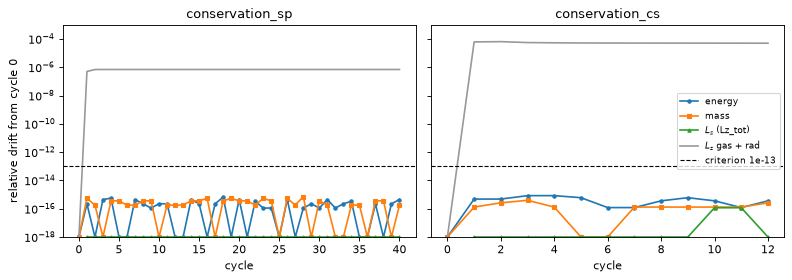

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, (t, base) in zip(axs, TESTS.items()):
    u = os.path.join(WORK, t, 'run', base + '.user.hst')
    h = os.path.join(WORK, t, 'run', base + '.hydro.hst')
    col = lambda f, n: nb.rt.hst_col(f, n)
    E, M = col(u, 'Eg') + col(u, 'Er'), col(h, 'mass')
    lzs = np.abs(col(u, 'Lgz')).max()
    Lz, Lgr = col(u, 'Lz_tot')[1:], col(u, 'Lgz') + col(u, 'Lrz')   # Lz_tot: from row 1
    cyc = np.arange(len(E))   # one history row per cycle
    tiny = 1e-18              # zero drift plotted at the axis floor
    ax.semilogy(cyc, np.maximum(abs(E - E[0])/abs(E[0]), tiny), 'o-', ms=3, label='energy')
    ax.semilogy(cyc, np.maximum(abs(M - M[0])/abs(M[0]), tiny), 's-', ms=3, label='mass')
    ax.semilogy(cyc[1:], np.maximum(abs(Lz - Lz[0])/lzs, tiny), '^-', ms=3, label='$L_z$ (Lz_tot)')
    ax.semilogy(cyc, np.maximum(abs(Lgr - Lgr[0])/lzs, tiny), '-', c='0.6', label='$L_z$ gas + rad')
    ax.axhline(1e-13, c='k', ls='--', lw=1, label='criterion 1e-13')
    ax.set(title=t, xlabel='cycle', ylim=(1e-18, 1e-3))
axs[0].set_ylabel('relative drift from cycle 0')
axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [4]:
for t in TESTS:
    print({k: v for k, v in res[t].items() if k != 'wall'})
    nb.verdict(t, res[t])

{'dE': 6.668693338721215e-16, 'dM': 7.194381405084556e-16, 'dLz': 0.0, 'dLz_gr': 6.942536901435344e-07}
PASS conservation_sp   criterion {"max": {"dE": 1e-13, "dM": 1e-13, "dLz": 1e-13}}
{'dE': 8.398502593257235e-16, 'dM': 3.914528838724328e-16, 'dLz': 1.1685200018258102e-16, 'dLz_gr': 6.438631872201e-05}
PASS conservation_cs   criterion {"max": {"dE": 1e-13, "dM": 1e-13, "dLz": 1e-13}}
